# Final Evaluation

In this notebook, we lock down our model architecture (XGBoost) and optimal hyperparameters found in Phase 11. 

We will combine the Training and Validation sets to maximize the data the model can learn from, train it one final time, and then evaluate it **exactly once** on the hold-out Test set (`X_test`).

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_curve, auc, average_precision_score, roc_auc_score
import sys
sys.path.append('..')

from src.preprocessing import load_and_clean_data, preprocess_and_split


In [2]:
data_path = '../data/raw/PS_20174392719_1491204439457_log.csv'
print("Loading Data...")
df = load_and_clean_data(data_path)
X_train, X_val, X_test, y_train, y_val, y_test, preprocessor = preprocess_and_split(df, val_size=0.15, test_size=0.15, random_state=42)

# Combine Train and Val
import scipy.sparse as sp
if sp.issparse(X_train):
    X_train_final = sp.vstack((X_train, X_val))
else:
    X_train_final = np.vstack((X_train, X_val))
y_train_final = np.concatenate((y_train, y_val))

print(f"Final Training shape: {X_train_final.shape}")
print(f"Test shape: {X_test.shape}")

Loading Data...


Final Training shape: (2354847, 10)
Test shape: (415562, 10)


In [3]:
import json
with open('../reports/hyperparameter_tuning.json', 'r') as f:
    tuning_results = json.load(f)

best_params = tuning_results['best_params']
scale_pos_weight = (y_train_final == 0).sum() / (y_train_final == 1).sum()
best_params['scale_pos_weight'] = scale_pos_weight
best_params['tree_method'] = 'hist'
best_params['random_state'] = 42
best_params['n_jobs'] = -1

print("Training Final Model with params:", best_params)
final_model = xgb.XGBClassifier(**best_params)
final_model.fit(X_train_final, y_train_final)
print("Training complete.")

Training Final Model with params: {'n_estimators': 126, 'max_depth': 5, 'learning_rate': 0.0677671238187077, 'subsample': 0.9036819393132569, 'colsample_bytree': 0.8691323646994898, 'scale_pos_weight': np.float64(336.32230339492907), 'tree_method': 'hist', 'random_state': 42, 'n_jobs': -1}


Training complete.


In [4]:
print("Predicting on hold-out Test Set...")
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

pr_auc = average_precision_score(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Final Test PR-AUC: {pr_auc:.4f}")
print(f"Final Test ROC-AUC: {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

with open('../reports/final_metrics.json', 'w') as f:
    json.dump({'pr_auc': pr_auc, 'roc_auc': roc_auc}, f, indent=4)


Predicting on hold-out Test Set...


Final Test PR-AUC: 0.9984
Final Test ROC-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.93      1.00      0.96      1232

    accuracy                           1.00    415562
   macro avg       0.96      1.00      0.98    415562
weighted avg       1.00      1.00      1.00    415562



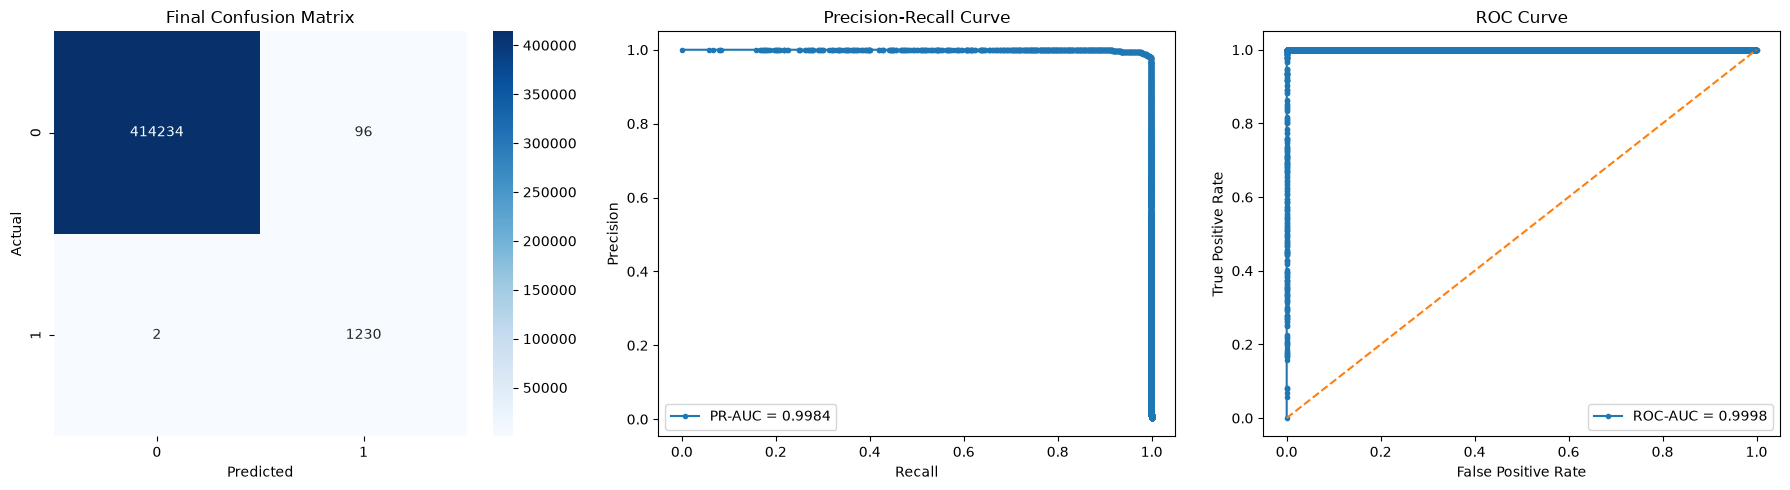

In [5]:
import os
os.makedirs('../reports/figures', exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Final Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# 2. PR Curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
axes[1].plot(recall, precision, marker='.', label=f'PR-AUC = {pr_auc:.4f}')
axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

# 3. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[2].plot(fpr, tpr, marker='.', label=f'ROC-AUC = {roc_auc:.4f}')
axes[2].plot([0, 1], [0, 1], linestyle='--')
axes[2].set_title('ROC Curve')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend()

plt.tight_layout()
plt.savefig('../reports/figures/final_evaluation_curves.png')
plt.show()

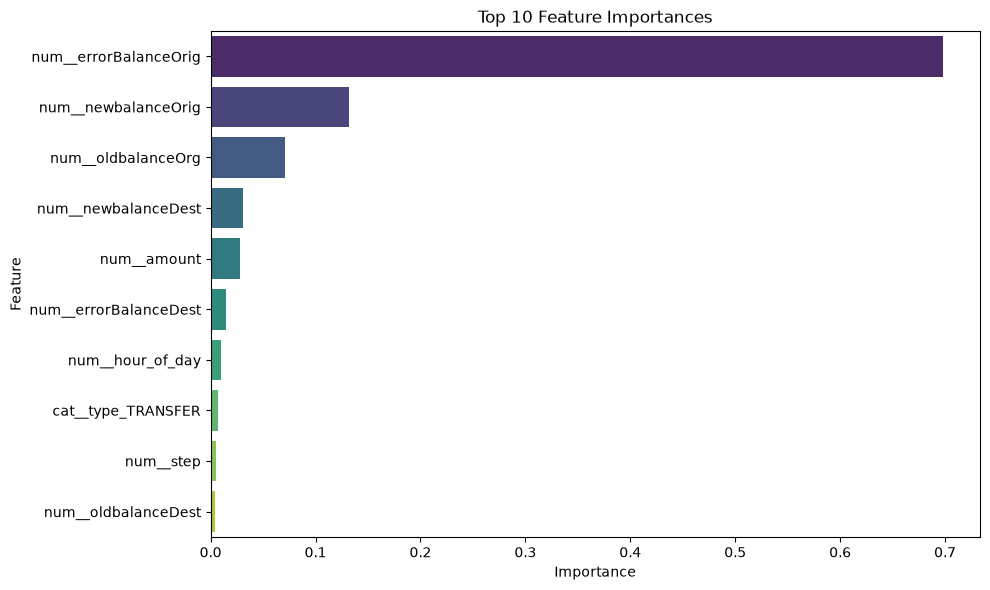

In [6]:
feature_names = preprocessor.get_feature_names_out()
importances = final_model.feature_importances_

feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('../reports/figures/feature_importances.png')
plt.show()